# MCMC-PESP: Analiza diagnostyczna na scenariuszach syntetycznych

Ten notebook realizuje eksperymenty z **MATH_SPEC.md Sekcja 10** ("Kwestie do zbadania empirycznie").

### Sekcje:
1. **Krajobraz kosztów** — kształt i trudność funkcji kosztu per scenariusz
2. **Zbieżność** — R-hat i ESS w funkcji kroków
3. **Porównanie propozycji** — która propozycja działa najlepiej?
4. **Parallel Tempering** — ile replik? Czy inercja pomaga?
5. **Skalowanie** — czas per krok vs rozmiar sieci
6. **Gap do optimum** — jak blisko optimum dociera MCMC?
7. **Podsumowanie** — tabela zbiorcza

### Jak czytać wyniki:
- Każda sekcja ma **opis co szukać** (markdown) + **kod** + **wizualizację**
- Parametry konfiguracyjne na górze — zmień `MODE` na `"full"` dla dłuższych runów
- Wyniki zapisywane do `results/diagnostics/` jako JSON

In [38]:
# ============================================================
# 0. KONFIGURACJA
# ============================================================

MODE = "full"  # "quick" (~1-2 min) lub "full" (~10-15 min)

SEED = 42
N_CHAINS = 4

if MODE == "quick":
    N_STEPS_CONVERGENCE = 10000
    N_STEPS_PROPOSALS = 5000
    N_STEPS_PT = 8000
    N_STEPS_GAP = 10000
    N_LANDSCAPE_SAMPLES = 500
    CHECKPOINT_EVERY = 1000
    GAP_CHECKPOINT_EVERY = 200
else:  # full
    N_STEPS_CONVERGENCE = 50000
    N_STEPS_PROPOSALS = 20000
    N_STEPS_PT = 30000
    N_STEPS_GAP = 50000
    N_LANDSCAPE_SAMPLES = 2000
    CHECKPOINT_EVERY = 2000
    GAP_CHECKPOINT_EVERY = 500

print(f"Mode: {MODE}")
print(f"Convergence: {N_STEPS_CONVERGENCE} steps x {N_CHAINS} chains")
print(f"Proposals: {N_STEPS_PROPOSALS} steps")
print(f"PT: {N_STEPS_PT} total budget")
print(f"Gap: {N_STEPS_GAP} steps")

Mode: full
Convergence: 50000 steps x 4 chains
Proposals: 20000 steps
PT: 30000 total budget
Gap: 50000 steps


In [39]:
import sys
import os
import json
import time
from pathlib import Path
from dataclasses import asdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (14, 5)
matplotlib.rcParams['font.size'] = 11

# Project root
PROJECT_ROOT = Path(os.getcwd()).parent if 'notebooks' in os.getcwd() else Path(os.getcwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.io.synthetic_scenarios import SyntheticScenarioFactory
from src.experiments.analysis.diagnostic_runner import (
    sample_cost_landscape,
    run_convergence_diagnostic,
    run_proposal_comparison,
    run_pt_diagnostic,
    run_scaling_analysis,
    run_optimum_gap_tracking,
)

factory = SyntheticScenarioFactory()
print(f"Available scenarios: {factory.list_scenarios()}")
print(f"Project root: {PROJECT_ROOT}")

Available scenarios: ['hub', 'chain', 'conflicting', 'weighted', 'full_cost', 'multi_hub_mesh', 'random_network']
Project root: C:\Users\User\Zeszyt\pythonProject\mcmc_pesp


---
## 1. Krajobraz kosztów (Cost Landscape)

**Pytanie z MATH_SPEC**: Jak wygląda rozkład kosztów dla losowych rozkładów jazdy?

**Co szukać**:
- **Rozrzut**: duży std/mean = trudny problem (wiele lokalnych minimów)
- **Skośność**: prawy ogon → większość rozwiązań jest "złych", optimum trudno znaleźć
- **Multimodalność**: wiele pików w histogramie = wiele basenów atrakcji
- **Min vs median**: duża różnica = istnieje dużo lepsze rozwiązanie niż typowe losowe

In [40]:
# Scenariusze do analizy landscape
landscape_specs = [
    ("hub", "easy"),
    ("hub", "hard"),
    ("chain", "easy"),
    ("chain", "hard"),
    ("conflicting", "easy"),
    ("conflicting", "medium"),
    ("weighted", "medium"),
    ("multi_hub_mesh", "easy"),
    ("multi_hub_mesh", "medium"),
    ("random_network", "medium"),
]

landscape_results = {}
for stype, diff in landscape_specs:
    kwargs = {"seed": 42} if stype == "random_network" else {}
    scenario = factory.create(stype, difficulty=diff, **kwargs)
    result = sample_cost_landscape(scenario, n_samples=N_LANDSCAPE_SAMPLES, seed=SEED)
    landscape_results[result.scenario_name] = result
    print(f"{result.scenario_name:35s} | mean={result.mean:12.1f} | std={result.std:12.1f} | "
          f"min={result.min_cost:10.1f} | median={result.median:10.1f}")

hub_easy                            | mean=   2117467.0 | std=   3888878.7 | min=     174.3 | median=    4510.3
hub_hard                            | mean=   8158272.6 | std=   7489454.1 | min=    6120.5 | median= 8006492.7
chain_easy                          | mean=    407267.1 | std=   1656199.9 | min=       1.1 | median=     832.2
chain_hard                          | mean=   1573641.9 | std=   3198764.3 | min=     249.5 | median=    3304.8
conflicting_easy                    | mean=    591958.1 | std=   1964286.1 | min=     160.5 | median=    1397.0
conflicting_medium                  | mean=    842782.7 | std=   2353690.3 | min=       3.2 | median=    1336.5
weighted_medium                     | mean= 104974070.6 | std= 260980660.3 | min=    4031.8 | median= 1192003.6
multi_hub_mesh_easy                 | mean= 339228140.0 | std= 376531045.2 | min=   23173.4 | median=250067446.0
multi_hub_mesh_medium               | mean= 499681732.5 | std= 458476751.5 | min=   83706.7 | median=41

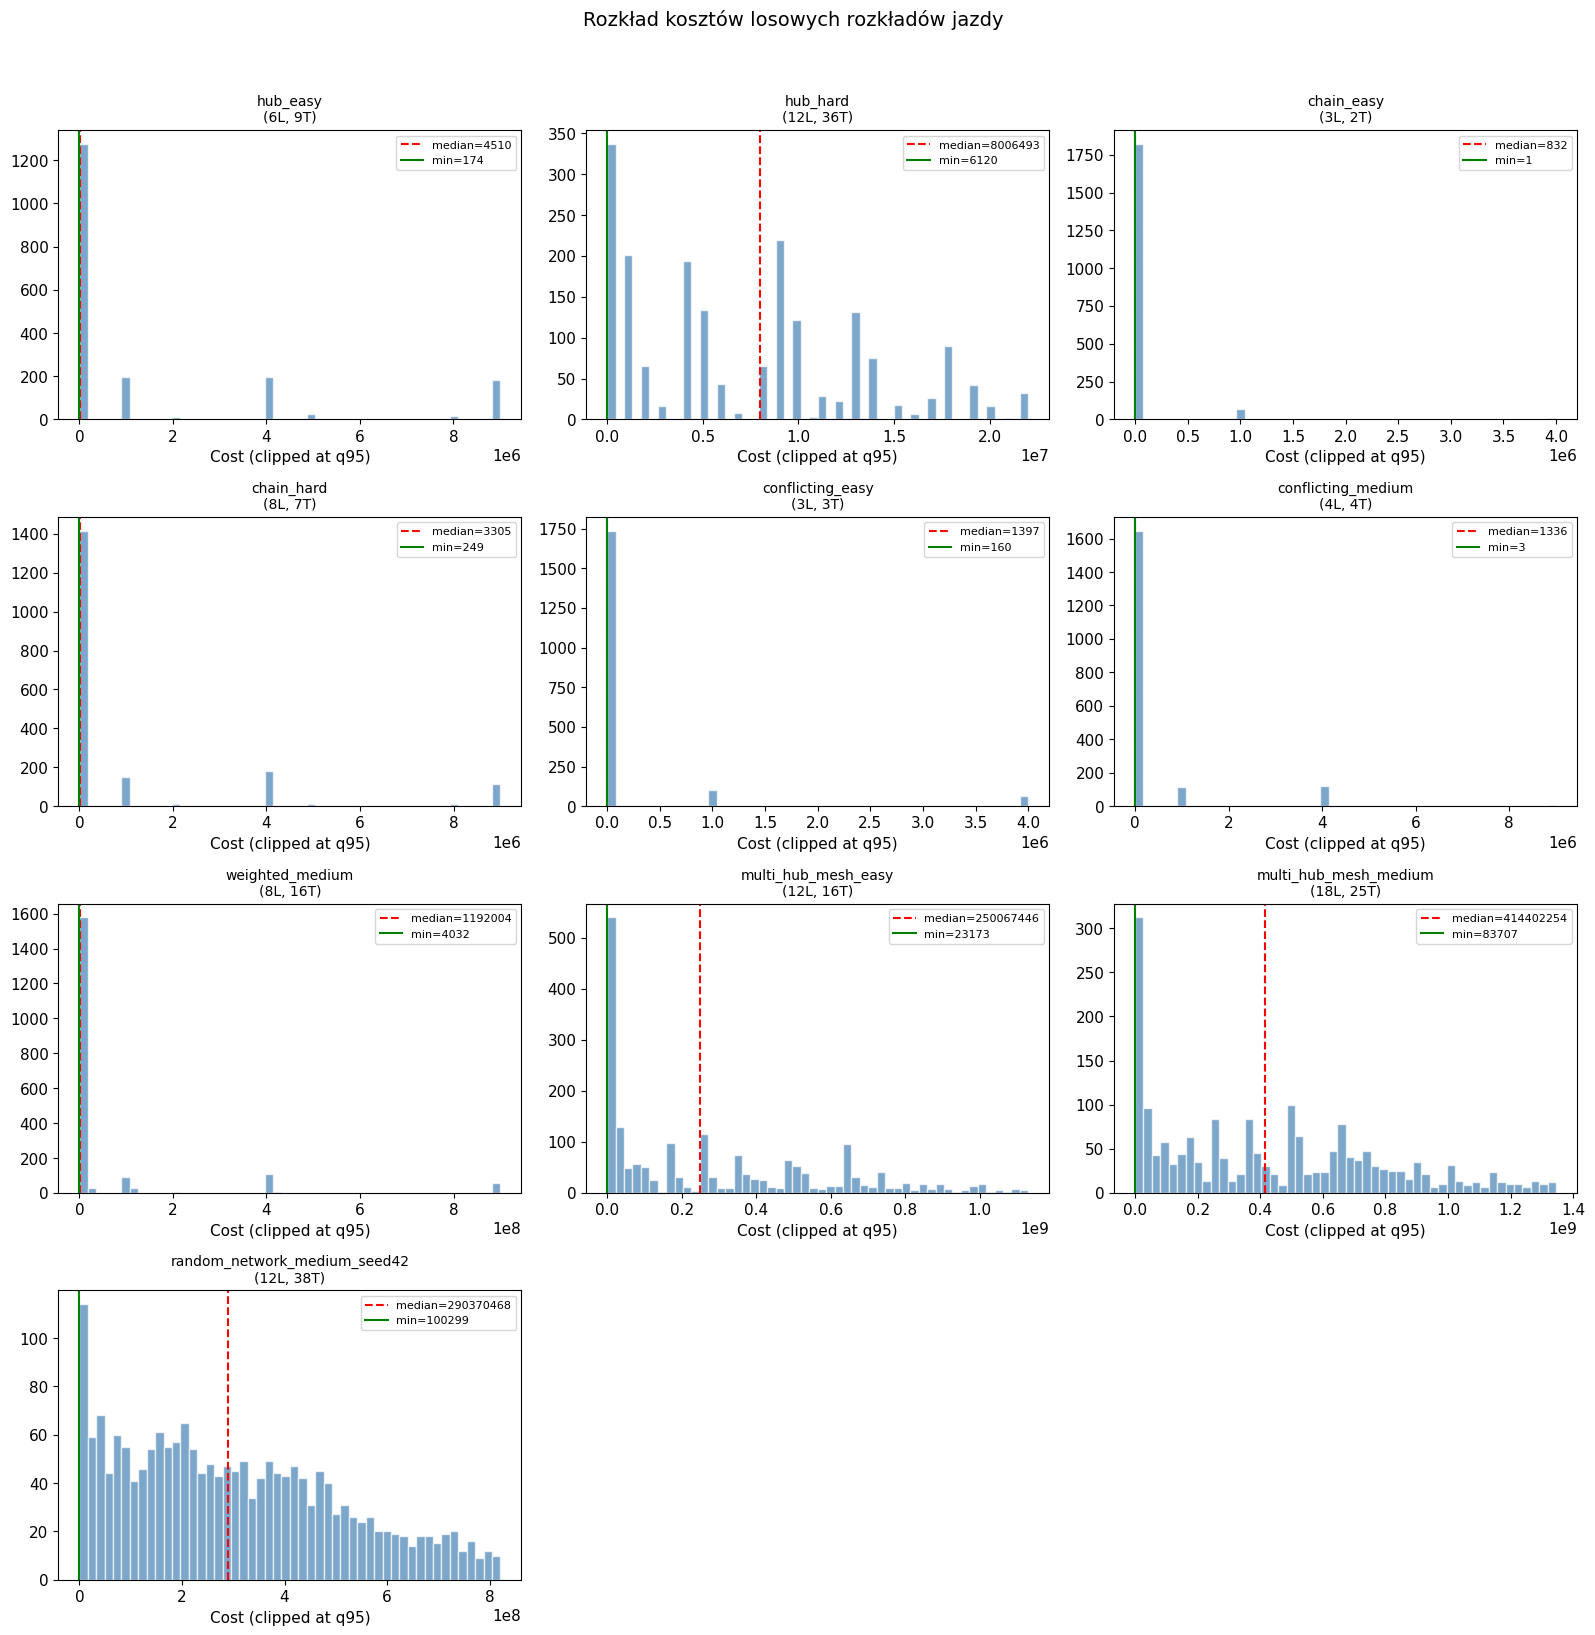

In [41]:
# Histogramy kosztów
n_plots = len(landscape_results)
n_cols = 3
n_rows = (n_plots + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, (name, result) in enumerate(landscape_results.items()):
    ax = axes[i]
    costs = np.array(result.costs)
    # Clip outliers for better visualization
    clip_high = np.percentile(costs, 95)
    costs_clipped = costs[costs <= clip_high]
    
    ax.hist(costs_clipped, bins=50, alpha=0.7, color='steelblue', edgecolor='white')
    ax.axvline(result.median, color='red', linestyle='--', label=f'median={result.median:.0f}')
    ax.axvline(result.min_cost, color='green', linestyle='-', label=f'min={result.min_cost:.0f}')
    ax.set_title(f"{name}\n({result.n_lines}L, {result.n_transfers}T)", fontsize=10)
    ax.set_xlabel('Cost (clipped at q95)')
    ax.legend(fontsize=8)

# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Rozkład kosztów losowych rozkładów jazdy', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [42]:
# Tabela podsumowująca landscape
print(f"{'Scenariusz':<35} {'Linie':>5} {'Trans':>5} {'Min':>12} {'Median':>12} "
      f"{'Mean':>12} {'Std':>12} {'Q95':>12} {'Std/Mean':>8}")
print("-" * 120)
for name, r in landscape_results.items():
    ratio = r.std / r.mean if r.mean > 0 else 0
    print(f"{name:<35} {r.n_lines:>5} {r.n_transfers:>5} {r.min_cost:>12.1f} {r.median:>12.1f} "
          f"{r.mean:>12.1f} {r.std:>12.1f} {r.q95:>12.1f} {ratio:>8.2f}")

Scenariusz                          Linie Trans          Min       Median         Mean          Std          Q95 Std/Mean
------------------------------------------------------------------------------------------------------------------------
hub_easy                                6     9        174.3       4510.3    2117467.0    3888878.7    9004769.9     1.84
hub_hard                               12    36       6120.5    8006492.7    8158272.6    7489454.1   22013532.1     0.92
chain_easy                              3     2          1.1        832.2     407267.1    1656199.9    4000041.2     4.07
chain_hard                              8     7        249.5       3304.8    1573641.9    3198764.3    9002847.2     2.03
conflicting_easy                        3     3        160.5       1397.0     591958.1    1964286.1    4000927.2     3.32
conflicting_medium                      4     4          3.2       1336.5     842782.7    2353690.3    9000133.7     2.79
weighted_medium          

---
## 2. Zbieżność (Convergence Diagnostics)

**Pytania z MATH_SPEC Sekcja 10.1**:
- Ile kroków do R-hat < 1.1?
- Jaki ESS/krok? (cel: > 0.01)
- Jak mixing skaluje się z rozmiarem sieci?

**Co szukać**:
- **R-hat → 1.0**: krzywa R-hat powinna opadać monotonicznie; jeśli oscyluje → problem z mixing
- **ESS rośnie liniowo**: jeśli plateau → łańcuch utknął
- **Trudniejsze scenariusze potrzebują więcej kroków**: hub_easy < hub_hard < mesh_medium

In [43]:
# Scenariusze do diagnostyki zbieżności
convergence_specs = [
    ("hub", "easy"),
    ("hub", "hard"),
    ("chain", "medium"),
    ("conflicting", "easy"),
    ("multi_hub_mesh", "easy"),
]

convergence_results = {}
for stype, diff in convergence_specs:
    kwargs = {"seed": 42} if stype == "random_network" else {}
    scenario = factory.create(stype, difficulty=diff, **kwargs)
    print(f"Running convergence diagnostic: {scenario.metadata.name}...")
    result = run_convergence_diagnostic(
        scenario, n_chains=N_CHAINS, n_steps=N_STEPS_CONVERGENCE,
        checkpoint_every=CHECKPOINT_EVERY, beta=1.0, seed=SEED,
    )
    convergence_results[result.scenario_name] = result
    status = 'CONVERGED' if result.converged else 'NOT converged'
    print(f"  {status} | R-hat={result.final_r_hat:.3f} | ESS={result.final_ess_total:.0f} "
          f"| steps_to_conv={result.steps_to_convergence} | time={result.wall_time_s:.1f}s")

Running convergence diagnostic: hub_easy...
  CONVERGED | R-hat=1.003 | ESS=700 | steps_to_conv=16000 | time=80.1s
Running convergence diagnostic: hub_hard...
  CONVERGED | R-hat=1.005 | ESS=326 | steps_to_conv=42000 | time=90.5s
Running convergence diagnostic: chain_medium...
  CONVERGED | R-hat=1.001 | ESS=1911 | steps_to_conv=10000 | time=43.1s
Running convergence diagnostic: conflicting_easy...
  CONVERGED | R-hat=1.001 | ESS=2600 | steps_to_conv=6000 | time=42.9s
Running convergence diagnostic: multi_hub_mesh_easy...
  NOT converged | R-hat=10492.220 | ESS=570 | steps_to_conv=None | time=93.7s


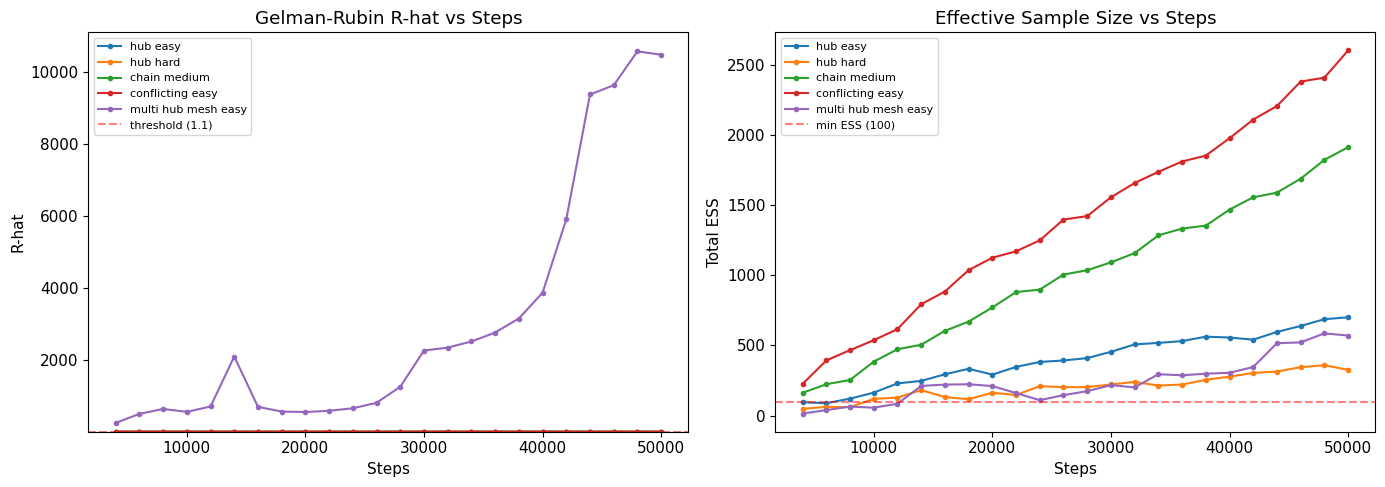

In [44]:
# R-hat vs steps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, result in convergence_results.items():
    steps = [cp.step for cp in result.checkpoints]
    r_hats = [cp.r_hat for cp in result.checkpoints]
    ess_totals = [cp.ess_total for cp in result.checkpoints]
    
    label = name.replace('_', ' ')
    ax1.plot(steps, r_hats, marker='o', markersize=3, label=label)
    ax2.plot(steps, ess_totals, marker='o', markersize=3, label=label)

ax1.axhline(1.1, color='red', linestyle='--', alpha=0.5, label='threshold (1.1)')
ax1.axhline(1.0, color='gray', linestyle=':', alpha=0.3)
ax1.set_xlabel('Steps')
ax1.set_ylabel('R-hat')
ax1.set_title('Gelman-Rubin R-hat vs Steps')
ax1.legend(fontsize=8)
ax1.set_ylim(0.95, max(2.0, ax1.get_ylim()[1]))

ax2.axhline(100, color='red', linestyle='--', alpha=0.5, label='min ESS (100)')
ax2.set_xlabel('Steps')
ax2.set_ylabel('Total ESS')
ax2.set_title('Effective Sample Size vs Steps')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [45]:
# Tabela zbieżności
print(f"{'Scenariusz':<35} {'R-hat':>7} {'ESS':>7} {'Steps->Conv':>12} "
      f"{'Accept':>7} {'Best Cost':>10} {'Converged':>10} {'Time(s)':>8}")
print("-" * 105)
for name, r in convergence_results.items():
    rh = f"{r.final_r_hat:.3f}" if r.final_r_hat else "N/A"
    stc = str(r.steps_to_convergence) if r.steps_to_convergence else ">" + str(r.total_steps)
    acc = f"{r.checkpoints[-1].acceptance_rate:.3f}" if r.checkpoints else "N/A"
    bc = f"{r.checkpoints[-1].best_cost:.1f}" if r.checkpoints else "N/A"
    print(f"{name:<35} {rh:>7} {r.final_ess_total:>7.0f} {stc:>12} "
          f"{acc:>7} {bc:>10} {str(r.converged):>10} {r.wall_time_s:>8.1f}")

Scenariusz                            R-hat     ESS  Steps->Conv  Accept  Best Cost  Converged  Time(s)
---------------------------------------------------------------------------------------------------------
hub_easy                              1.003     700        16000   0.371        3.1       True     80.1
hub_hard                              1.005     326        42000   0.384       12.6       True     90.5
chain_medium                          1.001    1911        10000   0.218        1.4       True     43.1
conflicting_easy                      1.001    2600         6000   0.302      160.5       True     42.9
multi_hub_mesh_easy                 10492.220     570       >50000   0.254     3114.0      False     93.7


---
## 3. Porównanie propozycji ruchów

**Pytania z MATH_SPEC Sekcja 10.2**:
- Która propozycja ma najlepszy ESS/krok? ESS/czas CPU?
- Optymalny mix wag?
- Czy Smart Repair przyspiesza zbieżność?

**Co szukać**:
- **Acceptance rate**: 20-50% to zdrowy zakres; <10% = za agresywne, >80% = za ostrożne
- **ESS/step**: im wyższe tym lepiej; component_move powinien dominować na sieciach z zależnościami
- **Smart Repair**: powinien mieć najniższy best_cost (celowane naprawy)

In [46]:
# Uruchom porównanie propozycji na multi_hub_mesh (najbardziej realistyczny)
scenario_for_proposals = factory.create('multi_hub_mesh', difficulty='easy')
print(f"Scenario: {scenario_for_proposals.metadata.name} "
      f"({scenario_for_proposals.metadata.n_lines}L, {scenario_for_proposals.metadata.n_transfers}T)")

proposal_result = run_proposal_comparison(
    scenario_for_proposals,
    n_steps=N_STEPS_PROPOSALS,
    n_chains=2,
    beta=1.0,
    seed=SEED,
)

print(f"\n{'Propozycja':<25} {'Accept':>8} {'Best Cost':>12} {'Mean Cost':>12} "
      f"{'ESS':>8} {'ESS/step':>10} {'ms/step':>8}")
print("-" * 90)
for e in proposal_result.entries:
    print(f"{e.proposal_name:<25} {e.acceptance_rate:>8.3f} {e.best_cost:>12.1f} {e.mean_cost:>12.1f} "
          f"{e.ess_total:>8.0f} {e.ess_per_step:>10.4f} {e.time_per_step_ms:>8.3f}")

Scenario: multi_hub_mesh_easy (12L, 16T)

Propozycja                  Accept    Best Cost    Mean Cost      ESS   ESS/step  ms/step
------------------------------------------------------------------------------------------
single_line_shift            0.175       3200.0      17316.1      243     0.0061    0.143
uniform_line_shift           0.142       3114.0      16391.7      286     0.0071    0.196
component_move               0.531       3114.0      25578.1       76     0.0019    0.578
smart_repair                 0.074       3184.0       6572.5     1544     0.0386    0.714
full_mix                     0.263       3114.0       4369.5      418     0.0104    0.370


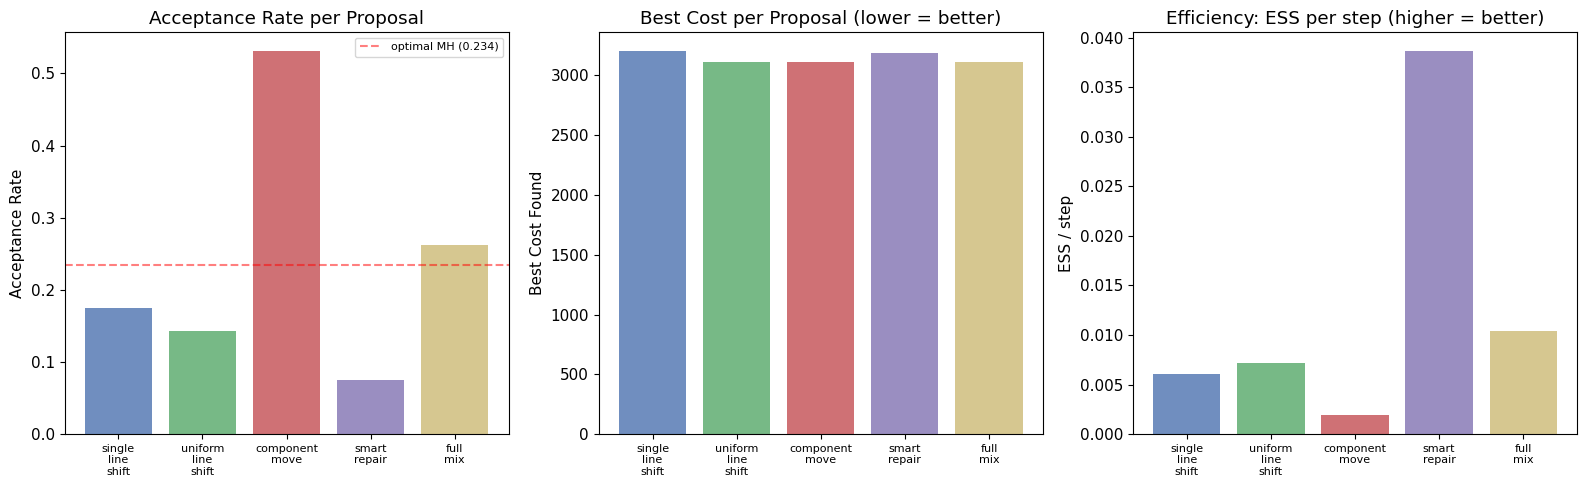

In [47]:
# Wizualizacja porównania propozycji
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

names = [e.proposal_name.replace('_', '\n') for e in proposal_result.entries]
x = np.arange(len(names))
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']

# Acceptance rate
rates = [e.acceptance_rate for e in proposal_result.entries]
axes[0].bar(x, rates, color=colors[:len(names)], alpha=0.8)
axes[0].axhline(0.234, color='red', linestyle='--', alpha=0.5, label='optimal MH (0.234)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(names, fontsize=8)
axes[0].set_ylabel('Acceptance Rate')
axes[0].set_title('Acceptance Rate per Proposal')
axes[0].legend(fontsize=8)

# Best cost
bests = [e.best_cost for e in proposal_result.entries]
axes[1].bar(x, bests, color=colors[:len(names)], alpha=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(names, fontsize=8)
axes[1].set_ylabel('Best Cost Found')
axes[1].set_title('Best Cost per Proposal (lower = better)')

# ESS/step
ess_per = [e.ess_per_step for e in proposal_result.entries]
axes[2].bar(x, ess_per, color=colors[:len(names)], alpha=0.8)
axes[2].set_xticks(x)
axes[2].set_xticklabels(names, fontsize=8)
axes[2].set_ylabel('ESS / step')
axes[2].set_title('Efficiency: ESS per step (higher = better)')

plt.tight_layout()
plt.show()

---
## 4. Parallel Tempering

**Pytania z MATH_SPEC Sekcja 10.3**:
- Ile replik optymalnie? (M = 4, 8, 16)
- Swap acceptance 20-30%?
- Czy inercja pomaga?

**Co szukać**:
- **Więcej replik = lepszy best_cost** ale droższy obliczeniowo (budżet podzielony)
- **Swap rates < 10%**: za duży rozstaw temperatur; **> 50%**: za mały
- **Inercja**: powinna pomagać na multi_hub_mesh (różne modality) ale nie na hub (jednorodny)

In [ ]:
# PT porównanie na multi_hub_mesh — poprawione parametry
# Poprzednio: replica_counts=[1,4,8], beta_min=0.1, beta_max=5.0 → swap rates <1% między zimnymi
# Teraz: więcej replik (do 16) + węższy zakres beta (0.5–3.0, ratio 6x zamiast 50x)
scenario_for_pt = factory.create('multi_hub_mesh', difficulty='easy')
print(f"Scenario: {scenario_for_pt.metadata.name}")
print(f"Params: beta_min=0.5, beta_max=3.0, replica_counts=[1, 4, 8, 12, 16], budget=60000\n")

pt_result = run_pt_diagnostic(
    scenario_for_pt,
    replica_counts=[1, 4, 8, 12, 16],
    n_steps=60000,
    beta_min=0.5,
    beta_max=3.0,
    test_inertia=True,
    seed=SEED,
)

print(f"\n{'Config':<30} {'Best Cost':>10} {'Mean Cost':>12} {'Swap Avg':>10} {'Swap Min':>10} {'Swap Max':>10} {'Time(s)':>8}")
print("-" * 100)
for e in pt_result.entries:
    tag = f"M={e.n_replicas}" + (" +inertia" if e.use_inertia else "")
    if e.swap_rates:
        avg_swap = f"{np.mean(e.swap_rates):.3f}"
        min_swap = f"{min(e.swap_rates):.3f}"
        max_swap = f"{max(e.swap_rates):.3f}"
    else:
        avg_swap = min_swap = max_swap = "N/A"
    print(f"{tag:<30} {e.best_cost:>10.1f} {e.cold_chain_mean_cost:>12.1f} "
          f"{avg_swap:>10} {min_swap:>10} {max_swap:>10} {e.wall_time_s:>8.1f}")

# Szczegółowe swap rates per pair
print("\n--- Swap rates per pair ---")
for e in pt_result.entries:
    if e.swap_rates:
        tag = f"M={e.n_replicas}" + (" +inertia" if e.use_inertia else "")
        rates_str = "  ".join(f"{i}-{i+1}:{s:.3f}" for i, s in enumerate(e.swap_rates))
        print(f"  {tag:<25} {rates_str}")

In [ ]:
# Wizualizacja PT — rozszerzona
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Best cost vs replicas
configs_no_inertia = [e for e in pt_result.entries if not e.use_inertia]
configs_inertia = [e for e in pt_result.entries if e.use_inertia]

if configs_no_inertia:
    axes[0].plot([e.n_replicas for e in configs_no_inertia],
                 [e.best_cost for e in configs_no_inertia],
                 'o-', label='Without inertia', color='steelblue', markersize=8)
if configs_inertia:
    axes[0].plot([e.n_replicas for e in configs_inertia],
                 [e.best_cost for e in configs_inertia],
                 's--', label='With inertia', color='coral', markersize=8)

axes[0].set_xlabel('Number of Replicas')
axes[0].set_ylabel('Best Cost Found')
axes[0].set_title('PT: Best Cost vs Replicas')
axes[0].legend()

# Average swap rate vs replicas
if configs_no_inertia:
    avg_swaps_no = [np.mean(e.swap_rates) if e.swap_rates else 0 for e in configs_no_inertia]
    axes[1].plot([e.n_replicas for e in configs_no_inertia], avg_swaps_no,
                 'o-', label='Without inertia', color='steelblue', markersize=8)
if configs_inertia:
    avg_swaps_in = [np.mean(e.swap_rates) if e.swap_rates else 0 for e in configs_inertia]
    axes[1].plot([e.n_replicas for e in configs_inertia], avg_swaps_in,
                 's--', label='With inertia', color='coral', markersize=8)

axes[1].axhline(0.2, color='green', linestyle='--', alpha=0.5, label='target min (0.2)')
axes[1].axhline(0.3, color='green', linestyle=':', alpha=0.5, label='target max (0.3)')
axes[1].set_xlabel('Number of Replicas')
axes[1].set_ylabel('Average Swap Rate')
axes[1].set_title('PT: Average Swap Rate vs Replicas')
axes[1].legend(fontsize=8)

# Swap rates per pair for best config
# Pick config with highest average swap rate
all_with_swaps = [e for e in pt_result.entries if e.swap_rates]
if all_with_swaps:
    best_swap_config = max(all_with_swaps, key=lambda e: np.mean(e.swap_rates))
    tag = f"M={best_swap_config.n_replicas}" + (" +inertia" if best_swap_config.use_inertia else "")
    pairs = list(range(len(best_swap_config.swap_rates)))
    colors_bar = ['steelblue' if s >= 0.1 else 'salmon' for s in best_swap_config.swap_rates]
    axes[2].bar(pairs, best_swap_config.swap_rates, color=colors_bar, alpha=0.8)
    axes[2].axhline(0.2, color='green', linestyle='--', alpha=0.5, label='target (0.2)')
    axes[2].set_xlabel('Replica Pair (i, i+1)')
    axes[2].set_ylabel('Swap Acceptance Rate')
    axes[2].set_title(f'Swap Rates per Pair ({tag})')
    axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## 5. Skalowanie

**Pytania z MATH_SPEC Sekcja 10.7**:
- Czas obliczeń vs |L| i |Gamma|
- Jaki jest exponent skalowania?

**Co szukać**:
- **Liniowe skalowanie** z |Gamma| (inkrementalny koszt) to dobry wynik
- **Nadliniowe** (kwadratowe+) oznacza wąskie gardło do profilowania

In [50]:
print("Running scaling analysis...")
scaling_result = run_scaling_analysis(n_steps=2000, beta=1.0, seed=SEED)

print(f"\n{'Scenariusz':<35} {'Linie':>5} {'Trans':>5} {'ms/step':>10} {'steps/s':>10}")
print("-" * 70)
for p in scaling_result.points:
    sps = 1000 / p.time_per_step_ms if p.time_per_step_ms > 0 else 0
    print(f"{p.scenario_name:<35} {p.n_lines:>5} {p.n_transfers:>5} "
          f"{p.time_per_step_ms:>10.3f} {sps:>10.0f}")

Running scaling analysis...

Scenariusz                          Linie Trans    ms/step    steps/s
----------------------------------------------------------------------
hub_easy                                6     9      0.141       7109
hub_medium                              8    16      0.171       5842
hub_hard                               12    36      0.268       3725
chain_easy                              3     2      0.113       8847
chain_hard                              8     7      0.127       7858
multi_hub_mesh_easy                    12    16      0.173       5788
multi_hub_mesh_medium                  18    25      0.214       4674
random_network_easy_seed42              6     9      0.142       7047
random_network_medium_seed42           12    38      0.281       3553
random_network_hard_seed42             20    82      0.437       2288


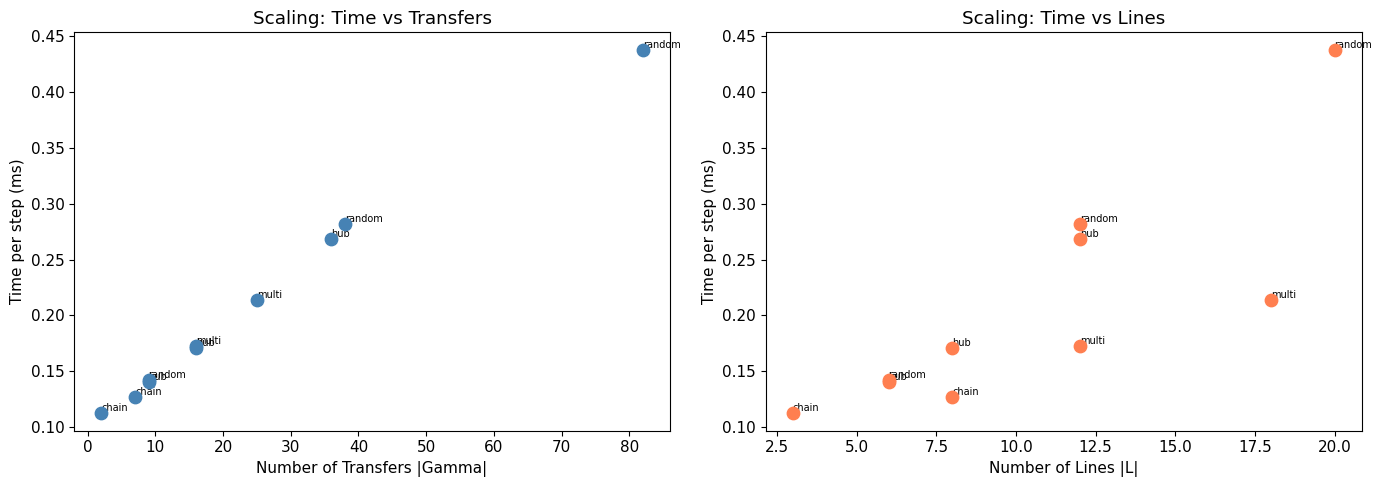

In [51]:
# Scaling plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

n_transfers = [p.n_transfers for p in scaling_result.points]
n_lines = [p.n_lines for p in scaling_result.points]
times = [p.time_per_step_ms for p in scaling_result.points]

ax1.scatter(n_transfers, times, s=80, c='steelblue', zorder=5)
for p in scaling_result.points:
    ax1.annotate(p.scenario_name.split('_')[0], (p.n_transfers, p.time_per_step_ms),
                 fontsize=7, ha='left', va='bottom')
ax1.set_xlabel('Number of Transfers |Gamma|')
ax1.set_ylabel('Time per step (ms)')
ax1.set_title('Scaling: Time vs Transfers')

ax2.scatter(n_lines, times, s=80, c='coral', zorder=5)
for p in scaling_result.points:
    ax2.annotate(p.scenario_name.split('_')[0], (p.n_lines, p.time_per_step_ms),
                 fontsize=7, ha='left', va='bottom')
ax2.set_xlabel('Number of Lines |L|')
ax2.set_ylabel('Time per step (ms)')
ax2.set_title('Scaling: Time vs Lines')

plt.tight_layout()
plt.show()

---
## 6. Gap do optimum (Known Optimum Gap)

**Pytanie**: Jak szybko MCMC zbliża się do known optimum?

**Co szukać**:
- **Krzywa gap vs steps**: powinna opadać; im szybciej tym lepiej
- **Hub powinien być łatwiejszy** niż chain (mniej zależności)
- **Gap → 0**: osiągnięte optimum; gap plateau → utknięcie w minimum lokalnym

In [52]:
# Gap tracking na scenariuszach ze znanym optimum
gap_specs = [
    ("hub", "easy"),
    ("hub", "medium"),
    ("chain", "easy"),
    ("chain", "medium"),
]

gap_results = {}
for stype, diff in gap_specs:
    scenario = factory.create(stype, difficulty=diff)
    print(f"Tracking gap: {scenario.metadata.name}...")
    result = run_optimum_gap_tracking(
        scenario, n_steps=N_STEPS_GAP,
        checkpoint_every=GAP_CHECKPOINT_EVERY,
        beta=2.0, seed=SEED,
    )
    gap_results[result.scenario_name] = result
    print(f"  optimal_cost={result.optimal_cost:.4f} | final_gap={result.final_gap:.4f} "
          f"| final_best={result.points[-1].best_cost:.2f} | time={result.wall_time_s:.1f}s")

Tracking gap: hub_easy...
  optimal_cost=3.1442 | final_gap=-0.0000 | final_best=3.14 | time=6.9s
Tracking gap: hub_medium...
  optimal_cost=5.5898 | final_gap=-0.0000 | final_best=5.59 | time=8.3s
Tracking gap: chain_easy...
  optimal_cost=0.6987 | final_gap=0.0000 | final_best=0.70 | time=5.1s
Tracking gap: chain_medium...
  optimal_cost=1.3974 | final_gap=-0.0000 | final_best=1.40 | time=5.3s


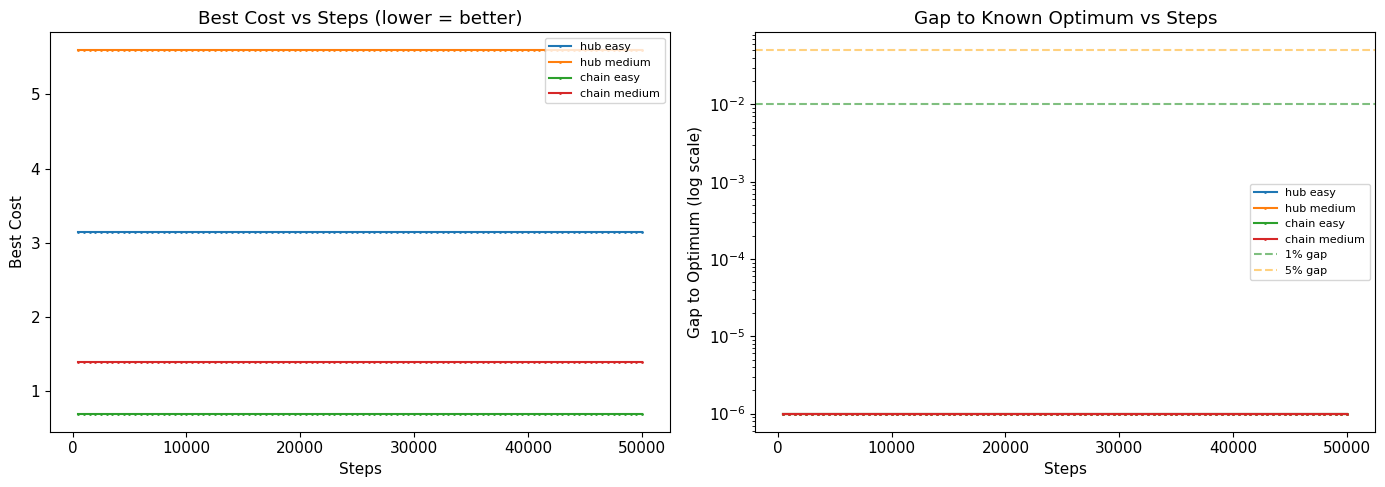

In [53]:
# Gap vs steps plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, result in gap_results.items():
    steps = [p.step for p in result.points]
    gaps = [p.gap for p in result.points]
    best_costs = [p.best_cost for p in result.points]
    
    label = name.replace('_', ' ')
    ax1.plot(steps, best_costs, marker='.', markersize=2, label=label)
    ax2.semilogy(steps, [max(g, 1e-6) for g in gaps], marker='.', markersize=2, label=label)

ax1.set_xlabel('Steps')
ax1.set_ylabel('Best Cost')
ax1.set_title('Best Cost vs Steps (lower = better)')
ax1.legend(fontsize=8)

ax2.axhline(0.01, color='green', linestyle='--', alpha=0.5, label='1% gap')
ax2.axhline(0.05, color='orange', linestyle='--', alpha=0.5, label='5% gap')
ax2.set_xlabel('Steps')
ax2.set_ylabel('Gap to Optimum (log scale)')
ax2.set_title('Gap to Known Optimum vs Steps')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## 7. Podsumowanie

Tabela zbiorcza wszystkich kluczowych metryk.

In [54]:
print("=" * 100)
print("PODSUMOWANIE DIAGNOSTYKI MCMC-PESP")
print(f"Mode: {MODE} | Steps: {N_STEPS_CONVERGENCE} | Chains: {N_CHAINS} | Seed: {SEED}")
print("=" * 100)

# 1. Convergence summary
print("\n--- ZBIEZNOSC ---")
print(f"{'Scenariusz':<35} {'R-hat':>7} {'ESS':>7} {'Conv?':>6} {'Steps->Conv':>12}")
for name, r in convergence_results.items():
    rh = f"{r.final_r_hat:.3f}" if r.final_r_hat else "N/A"
    stc = str(r.steps_to_convergence) if r.steps_to_convergence else f">{r.total_steps}"
    print(f"{name:<35} {rh:>7} {r.final_ess_total:>7.0f} {'Yes' if r.converged else 'No':>6} {stc:>12}")

# 2. Proposal summary
print("\n--- PROPOZYCJE (na multi_hub_mesh) ---")
print(f"{'Propozycja':<25} {'Accept':>8} {'Best Cost':>10} {'ESS/step':>10}")
for e in proposal_result.entries:
    print(f"{e.proposal_name:<25} {e.acceptance_rate:>8.3f} {e.best_cost:>10.1f} {e.ess_per_step:>10.4f}")

# 3. PT summary
print("\n--- PARALLEL TEMPERING ---")
print(f"{'Config':<30} {'Best Cost':>10} {'Swap Rate Avg':>14}")
for e in pt_result.entries:
    tag = f"M={e.n_replicas}" + (" +inertia" if e.use_inertia else "")
    avg_swap = f"{np.mean(e.swap_rates):.3f}" if e.swap_rates else "N/A"
    print(f"{tag:<30} {e.best_cost:>10.1f} {avg_swap:>14}")

# 4. Gap summary
print("\n--- GAP DO OPTIMUM ---")
print(f"{'Scenariusz':<35} {'Optimal':>10} {'Best Found':>10} {'Gap':>10}")
for name, r in gap_results.items():
    print(f"{name:<35} {r.optimal_cost:>10.2f} {r.points[-1].best_cost:>10.2f} {r.final_gap:>10.4f}")

print("\n" + "=" * 100)

PODSUMOWANIE DIAGNOSTYKI MCMC-PESP
Mode: full | Steps: 50000 | Chains: 4 | Seed: 42

--- ZBIEZNOSC ---
Scenariusz                            R-hat     ESS  Conv?  Steps->Conv
hub_easy                              1.003     700    Yes        16000
hub_hard                              1.005     326    Yes        42000
chain_medium                          1.001    1911    Yes        10000
conflicting_easy                      1.001    2600    Yes         6000
multi_hub_mesh_easy                 10492.220     570     No       >50000

--- PROPOZYCJE (na multi_hub_mesh) ---
Propozycja                  Accept  Best Cost   ESS/step
single_line_shift            0.175     3200.0     0.0061
uniform_line_shift           0.142     3114.0     0.0071
component_move               0.531     3114.0     0.0019
smart_repair                 0.074     3184.0     0.0386
full_mix                     0.263     3114.0     0.0104

--- PARALLEL TEMPERING ---
Config                          Best Cost  Swap Rate 

In [55]:
# Zapisz wyniki do JSON
output_dir = PROJECT_ROOT / "results" / "diagnostics"
output_dir.mkdir(parents=True, exist_ok=True)

summary = {
    "mode": MODE,
    "seed": SEED,
    "n_chains": N_CHAINS,
    "convergence": {
        name: {
            "r_hat": r.final_r_hat,
            "ess_total": r.final_ess_total,
            "converged": r.converged,
            "steps_to_convergence": r.steps_to_convergence,
            "total_steps": r.total_steps,
        }
        for name, r in convergence_results.items()
    },
    "proposals": [
        {
            "name": e.proposal_name,
            "acceptance_rate": e.acceptance_rate,
            "best_cost": e.best_cost,
            "ess_per_step": e.ess_per_step,
        }
        for e in proposal_result.entries
    ],
    "pt": [
        {
            "n_replicas": e.n_replicas,
            "use_inertia": e.use_inertia,
            "best_cost": e.best_cost,
            "swap_rates": e.swap_rates,
        }
        for e in pt_result.entries
    ],
    "gap": {
        name: {
            "optimal_cost": r.optimal_cost,
            "final_gap": r.final_gap,
            "final_best_cost": r.points[-1].best_cost,
        }
        for name, r in gap_results.items()
    },
}

output_path = output_dir / f"diagnostics_{MODE}.json"
with open(output_path, "w") as f:
    json.dump(summary, f, indent=2)
print(f"Results saved to {output_path}")

Results saved to C:\Users\User\Zeszyt\pythonProject\mcmc_pesp\results\diagnostics\diagnostics_full.json
